In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [4]:
df = pd.read_csv("winequality-red.csv")
print("Shape:", df.shape)
df.head()

Shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [5]:
print(df.info())
print()
print("Missing values per column:")
print(df.isna().sum())
print()
print("Quality score distribution:")
print(df["quality"].value_counts().sort_index())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB
None

Missing values per column:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar 

Correlation between alcohol and quality: 0.476


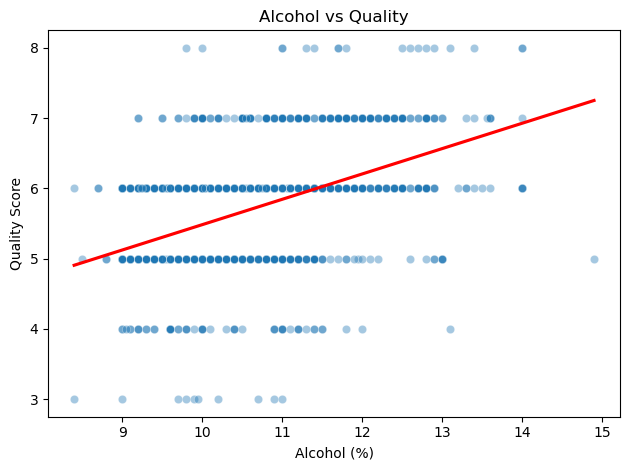

In [13]:
corr_alcohol_quality = df["alcohol"].corr(df["quality"])
print(f"Correlation between alcohol and quality: {corr_alcohol_quality:.3f}")
# print(round(corr_alcohol_quality,3))
# corr_with_quality_sorted.round(3)
# print("Correlation between alcohol and quality:", np.round(corr_alcohol_quality, 3))
# print("Correlation between alcohol and quality: {:.3f}".format(corr_alcohol_quality))
# print("Correlation between alcohol and quality: %.3f" % corr_alcohol_quality)
sns.scatterplot(data=df, x="alcohol", y="quality", alpha=0.4)
sns.regplot(data=df, x="alcohol", y="quality", scatter=False, color="red", ci=None)
plt.title("Alcohol vs Quality")
plt.xlabel("Alcohol (%)")
plt.ylabel("Quality Score")
plt.tight_layout()
plt.show()

-0.391


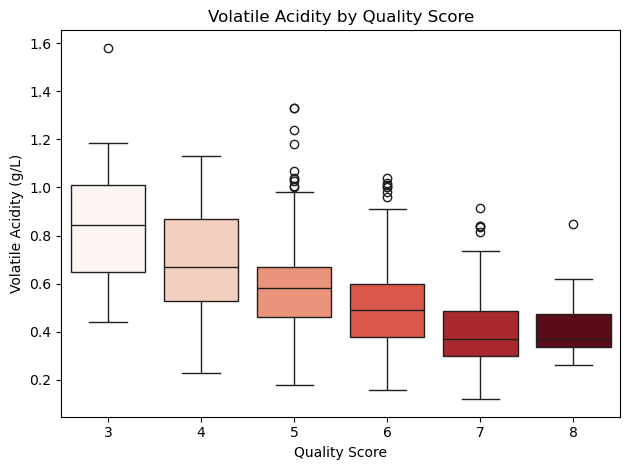

In [18]:
corr_va_quality = df["volatile acidity"].corr(df["quality"])
print(np.round(corr_va_quality,3))
sns.boxplot(data=df, x="quality", y="volatile acidity", hue="quality", palette="Reds", legend=False) # Legend bydefault True then shows the category wise values
plt.title("Volatile Acidity by Quality Score")
plt.xlabel("Quality Score")
plt.ylabel("Volatile Acidity (g/L)")
plt.tight_layout()
plt.show()

In [23]:
low_q = df[df["quality"] <= 4]
high_q = df[df["quality"] >= 7]
citric_comparison = pd.DataFrame({
    "Low Quality (<=4)": low_q["citric acid"].describe(),
    "High Quality (>=7)": high_q["citric acid"].describe()
}) # To do comparsion used condition & represented via dataframe
citric_comparison

,Low Quality (<=4),High Quality (>=7)
count,63.000000,217.000000
mean,0.173651,0.376498
std,0.207406,0.194438
min,0.000000,0.000000
25%,0.020000,0.300000
50%,0.080000,0.400000
75%,0.270000,0.490000
max,1.000000,0.760000


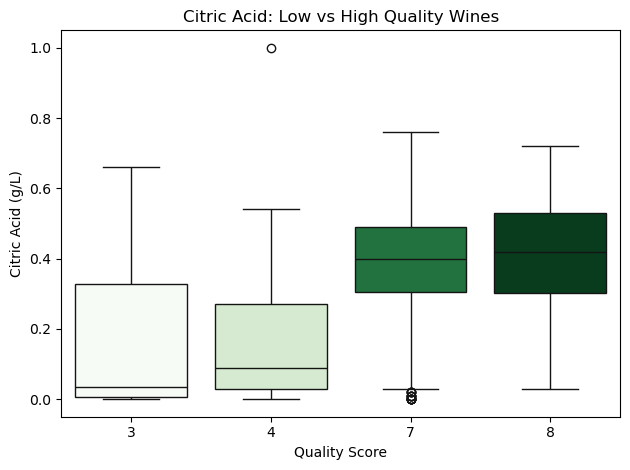

In [24]:
sns.boxplot(
    data=df[df["quality"].isin([3, 4, 7, 8])],
    x="quality", y="citric acid", hue="quality", palette="Greens", legend=False
)
plt.title("Citric Acid: Low vs High Quality Wines")
plt.xlabel("Quality Score")
plt.ylabel("Citric Acid (g/L)")
plt.tight_layout()
plt.show()
# .isin() checks each row's quality value against a list, returning True if it matches any of the listed values, False otherwise. So this keeps only rows where quality is exactly 3, 4, 7, or 8.

         median      mean       std   min   max
quality                                        
3          3.39  3.398000  0.144052  3.16  3.63
4          3.37  3.381509  0.181441  2.74  3.90
5          3.30  3.304949  0.150618  2.88  3.74
6          3.32  3.318072  0.153995  2.86  4.01
7          3.28  3.290754  0.150101  2.92  3.78
8          3.23  3.267222  0.200640  2.88  3.72


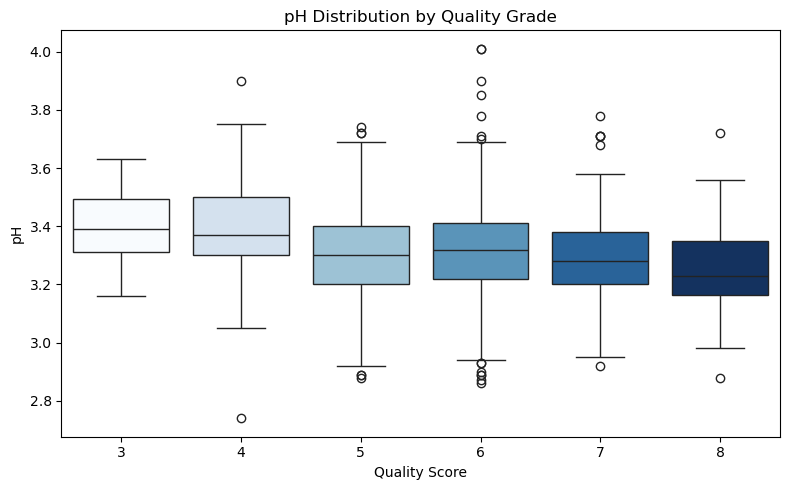

In [30]:
ph_by_quality = df.groupby("quality")["pH"].agg(["median", "mean", "std", "min", "max"])
print(ph_by_quality)

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="quality", y="pH", hue="quality", palette="Blues", legend=False)
plt.title("pH Distribution by Quality Grade")
plt.xlabel("Quality Score")
plt.ylabel("pH")
plt.tight_layout()
plt.show()


Correlation between residual sugar and density: 0.355


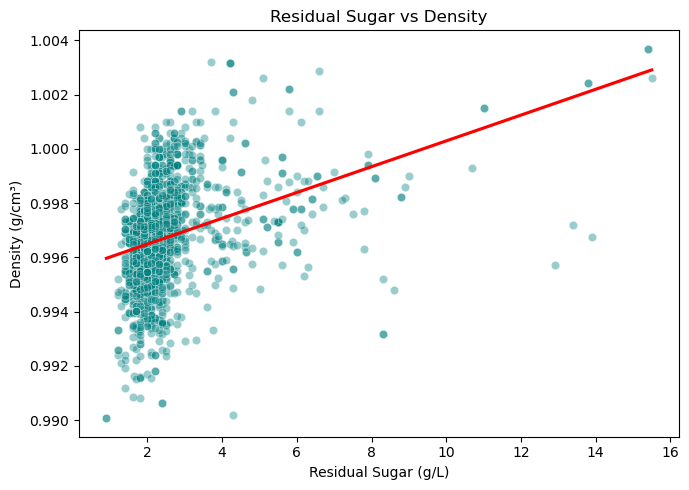

In [31]:
corr_sugar_density = df["residual sugar"].corr(df["density"])
print(f"Correlation between residual sugar and density: {corr_sugar_density:.3f}")

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="residual sugar", y="density", alpha=0.4, color="teal")
sns.regplot(data=df, x="residual sugar", y="density", scatter=False, color="red", ci=None)
plt.title("Residual Sugar vs Density")
plt.xlabel("Residual Sugar (g/L)")
plt.ylabel("Density (g/cm³)")
plt.tight_layout()
plt.show()


Correlation between free/total SO2 ratio and quality: 0.194
quality
3    0.436593
4    0.387507
5    0.339166
6    0.409621
7    0.436107
8    0.406467
Name: free_total_so2_ratio, dtype: float64


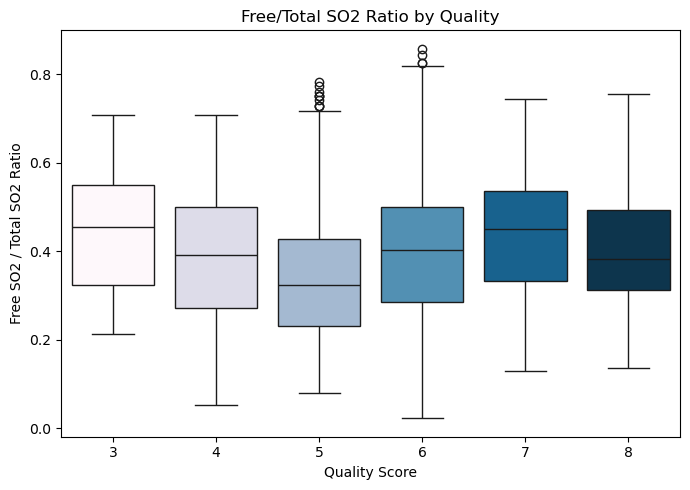

In [32]:
df["free_total_so2_ratio"] = df["free sulfur dioxide"] / df["total sulfur dioxide"]

corr_ratio_quality = df["free_total_so2_ratio"].corr(df["quality"])
print(f"Correlation between free/total SO2 ratio and quality: {corr_ratio_quality:.3f}")

ratio_by_quality = df.groupby("quality")["free_total_so2_ratio"].mean()
print(ratio_by_quality)

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="quality", y="free_total_so2_ratio", hue="quality", palette="PuBu", legend=False)
plt.title("Free/Total SO2 Ratio by Quality")
plt.xlabel("Quality Score")
plt.ylabel("Free SO2 / Total SO2 Ratio")
plt.tight_layout()
plt.show()


All feature correlations with quality (most negative first):
volatile acidity       -0.390558
total sulfur dioxide   -0.185100
density                -0.174919
chlorides              -0.128907
pH                     -0.057731
free sulfur dioxide    -0.050656
residual sugar          0.013732
fixed acidity           0.124052
citric acid             0.226373
sulphates               0.251397
alcohol                 0.476166
Name: quality, dtype: float64


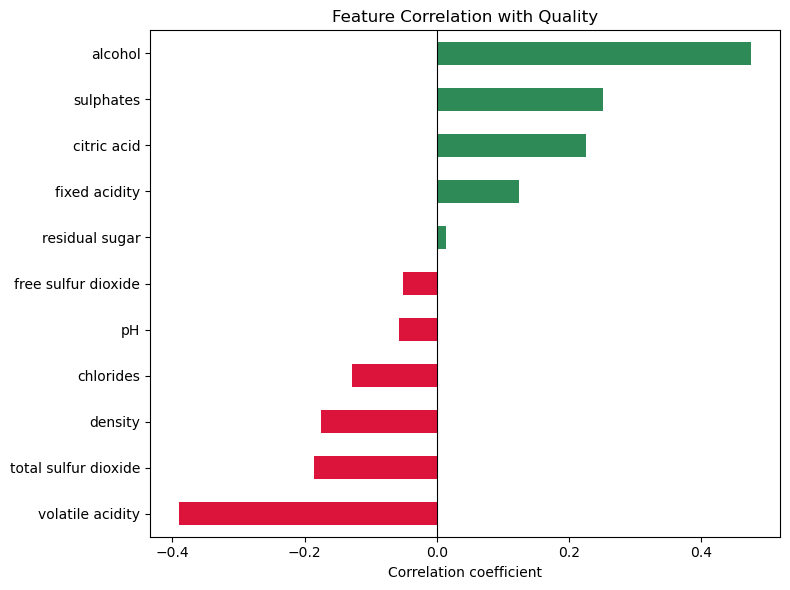


Strongest inverse relationship: 'volatile acidity' (r = -0.391)


In [33]:
feature_cols = [c for c in df.columns if c not in ["quality", "quality_tier", "free_total_so2_ratio"]]

corr_with_quality = df[feature_cols + ["quality"]].corr()["quality"].drop("quality")
corr_with_quality_sorted = corr_with_quality.sort_values()

print("All feature correlations with quality (most negative first):")
print(corr_with_quality_sorted)

plt.figure(figsize=(8, 6))
corr_with_quality_sorted.plot(kind="barh", color=corr_with_quality_sorted.apply(lambda x: "crimson" if x < 0 else "seagreen"))
plt.title("Feature Correlation with Quality")
plt.xlabel("Correlation coefficient")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

most_negative = corr_with_quality_sorted.index[0]
print(f"\nStrongest inverse relationship: '{most_negative}' (r = {corr_with_quality_sorted.iloc[0]:.3f})")


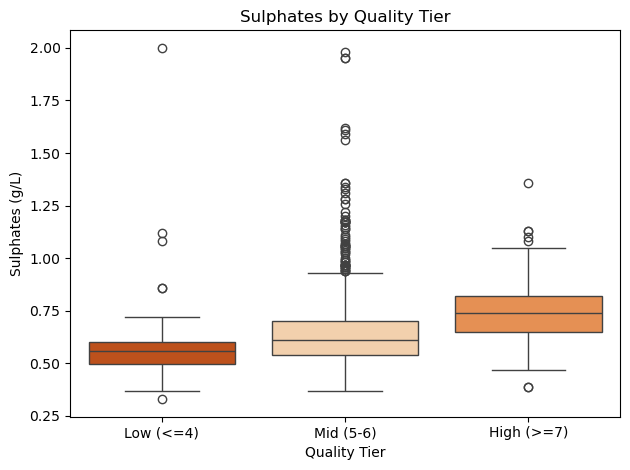

In [36]:
def quality_tier(q):
    if q <= 4:
        return "Low (<=4)"
    elif q <= 6:
        return "Mid (5-6)"
    else:
        return "High (>=7)"

df["quality_tier"] = df["quality"].apply(quality_tier)
df["quality_tier"].value_counts()

premium = df[df["quality"] >= 7]
standard = df[df["quality"] <= 6]

sulphate_comparison = pd.DataFrame({
    "Premium (quality>=7)": premium["sulphates"].describe(),
    "Standard (quality<=6)": standard["sulphates"].describe()
})
sulphate_comparison
sns.boxplot(data=df, x="quality_tier", y="sulphates",
            order=["Low (<=4)", "Mid (5-6)", "High (>=7)"],
            hue="quality_tier", palette="Oranges", legend=False)
plt.title("Sulphates by Quality Tier")
plt.xlabel("Quality Tier")
plt.ylabel("Sulphates (g/L)")
plt.tight_layout()
plt.show()

Mean chlorides — Top-tier (quality>=7):   0.0759
Mean chlorides — Lower-tier (quality<=6): 0.0893


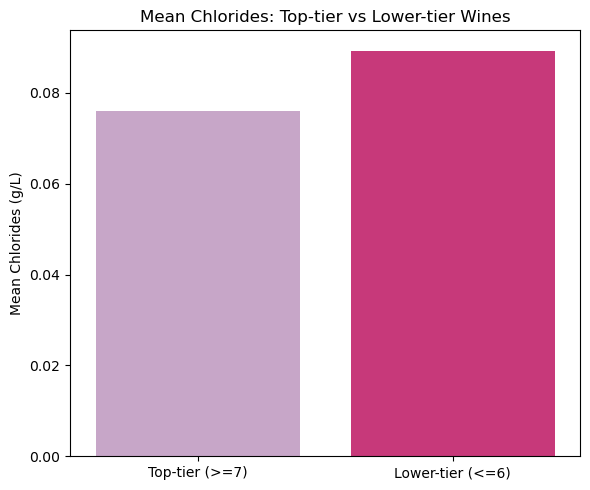

In [37]:
top_tier = df[df["quality"] >= 7]
lower_tier = df[df["quality"] <= 6]

print(f"Mean chlorides — Top-tier (quality>=7):   {top_tier['chlorides'].mean():.4f}")
print(f"Mean chlorides — Lower-tier (quality<=6): {lower_tier['chlorides'].mean():.4f}")

plt.figure(figsize=(6, 5))
sns.barplot(
    x=["Top-tier (>=7)", "Lower-tier (<=6)"],
    y=[top_tier["chlorides"].mean(), lower_tier["chlorides"].mean()],
    hue=["Top-tier (>=7)", "Lower-tier (<=6)"], palette="PuRd", legend=False
)
plt.title("Mean Chlorides: Top-tier vs Lower-tier Wines")
plt.ylabel("Mean Chlorides (g/L)")
plt.tight_layout()
plt.show()


In [38]:
acidity_cols = ["fixed acidity", "volatile acidity", "citric acid"]

acidity_by_tier = df.groupby("quality_tier")[acidity_cols].mean().reindex(
    ["Low (<=4)", "Mid (5-6)", "High (>=7)"]
)
acidity_by_tier


,fixed acidity,volatile acidity,citric acid
quality_tier,,,
Low (<=4),7.871429,0.724206,0.173651
Mid (5-6),8.254284,0.538560,0.258264
High (>=7),8.847005,0.405530,0.376498


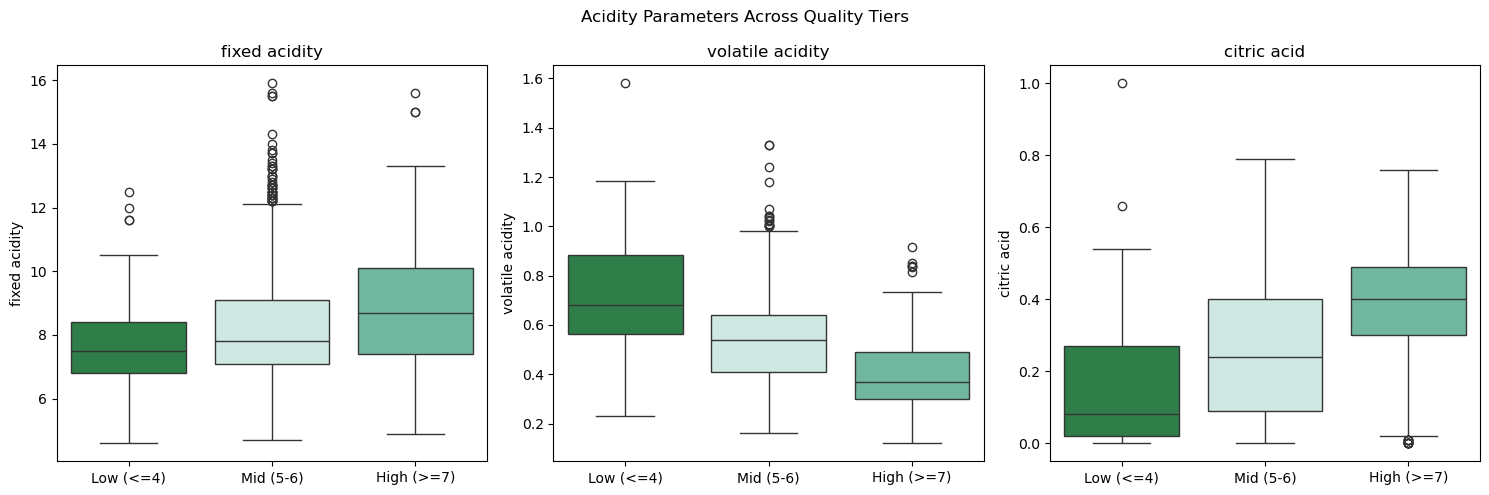

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col in zip(axes, acidity_cols):
    sns.boxplot(data=df, x="quality_tier", y=col,
                order=["Low (<=4)", "Mid (5-6)", "High (>=7)"],
                hue="quality_tier", palette="BuGn", legend=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Acidity Parameters Across Quality Tiers")
plt.tight_layout()
plt.show()
